<a href="https://colab.research.google.com/github/Izyakowich/mephi-rec_sys_hw/blob/main/book_recommendations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Прототип книжного рекомендательного сервиса



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams['figure.figsize'] = (9, 4)
DATA_DIR = Path('.')
if not (DATA_DIR / 'ratings.csv').exists() and Path('/content/archive/ratings.csv').exists():
    DATA_DIR = Path('/content/archive')

ratings = pd.read_csv(DATA_DIR / 'ratings.csv')
books = pd.read_csv(DATA_DIR / 'books.csv')
tags = pd.read_csv(DATA_DIR / 'tags.csv')
book_tags = pd.read_csv(DATA_DIR / 'book_tags.csv')
print('Оценки:', ratings.shape, '| Книги:', books.shape)
print('Теги:', tags.shape, '| Теги книг:', book_tags.shape)
print(ratings.head())

Оценки: (981756, 3) | Книги: (10000, 23)
Теги: (34252, 2) | Теги книг: (999912, 3)
   book_id  user_id  rating
0        1      314       5
1        1      439       3
2        1      588       5
3        1     1169       4
4        1     1185       4


## 1. EDA: знакомство с данными

Сначала посмотрим на распределение оценок, активность читателей , популярностб книг и теги. Повторные оценки одной пары пользователь - книга удаляем, оставляя последнюю запись

In [ ]:
print('Пропуски в ratings:')
print(ratings.isna().sum())
print('Дубли (user_id, book_id):', ratings.duplicated(['user_id', 'book_id']).sum())
ratings = ratings.drop_duplicates(['user_id', 'book_id'], keep='last').copy()
ratings = ratings[ratings.book_id.isin(books.id)].reset_index(drop=True)
print('После очистки:', len(ratings), 'оценок')
print('Уникальных пользователей:', ratings.user_id.nunique())
print('Уникальных книг:', ratings.book_id.nunique())

Пропуски в ratings:
book_id    0
user_id    0
rating     0
dtype: int64
Дубли (user_id, book_id): 2278
После очистки: 979478 оценок
Уникальных пользователей: 53424
Уникальных книг: 10000


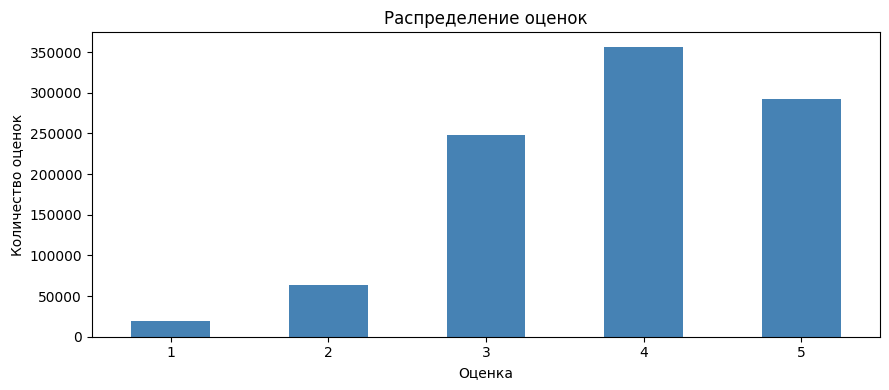

Доля оценок 4–5: 66.2%


In [ ]:
counts = ratings.rating.value_counts().sort_index()
counts.plot.bar(color='steelblue')
plt.title('Распределение оценок')
plt.xlabel('Оценка')
plt.ylabel('Количество оценок')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print(f'Доля оценок 4–5: {ratings.rating.ge(4).mean():.1%}')

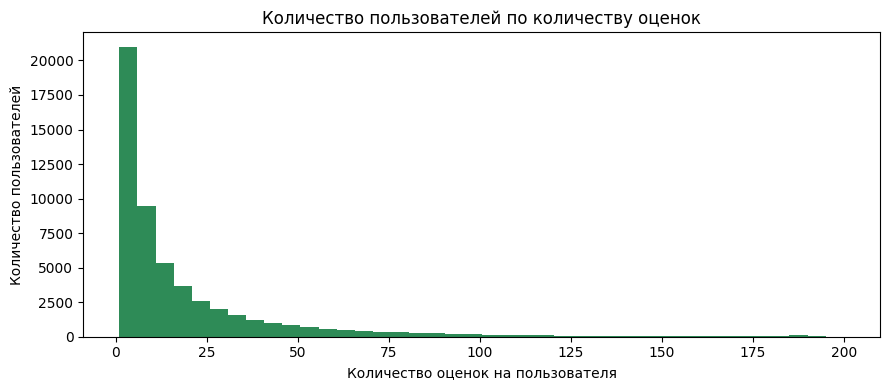

Пользователей с 5 и менее оценками: 20985
Пользователей с 50 и более оценками: 4908
Медиана числа оценок: 8.0


In [ ]:
user_activity = ratings.groupby('user_id').size()
plt.hist(user_activity, bins=40, color='seagreen')
plt.title('Количество пользователей по количеству оценок')
plt.xlabel('Количество оценок на пользователя')
plt.ylabel('Количество пользователей')
plt.tight_layout()
plt.show()
print('Пользователей с 5 и менее оценками:', (user_activity <= 5).sum())
print('Пользователей с 50 и более оценками:', (user_activity >= 50).sum())
print('Медиана числа оценок:', user_activity.median())

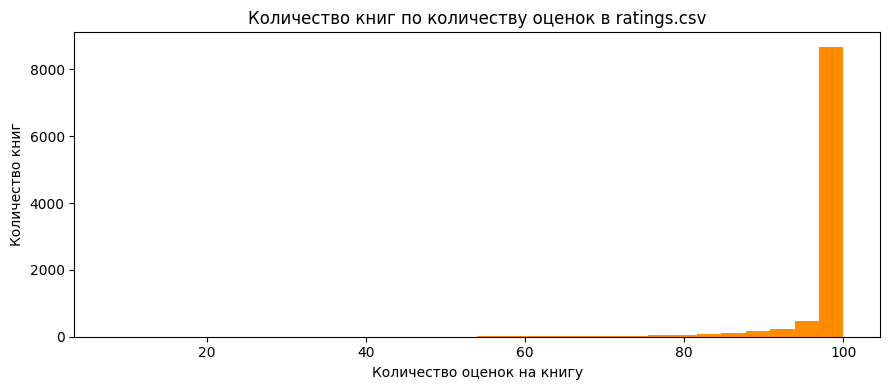

Максимум оценок на книгу в ratings.csv: 100
Книг ровно со 100 оценками: 6248


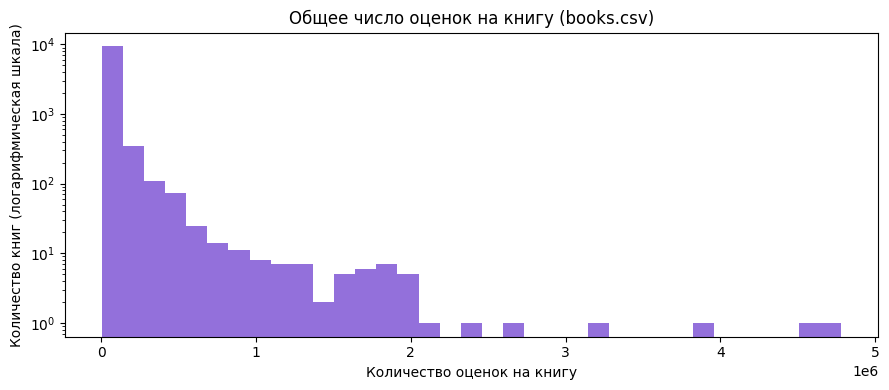

In [ ]:
book_activity = ratings.groupby('book_id').size()
plt.hist(book_activity, bins=30, color='darkorange')
plt.title('Количество книг по количеству оценок в ratings.csv')
plt.xlabel('Количество оценок на книгу')
plt.ylabel('Количество книг')
plt.tight_layout()
plt.show()
print('Максимум оценок на книгу в ratings.csv:', book_activity.max())
print('Книг ровно со 100 оценками:', (book_activity == 100).sum())

# Более реальную картину популярности показывает общий счетчик из books.csv.
plt.hist(books.ratings_count, bins=35, color='mediumpurple')
plt.yscale('log')
plt.title('Общее число оценок на книгу (books.csv)')
plt.xlabel('Количество оценок на книгу')
plt.ylabel('Количество книг (логарифмическая шкала)')
plt.tight_layout()
plt.show()

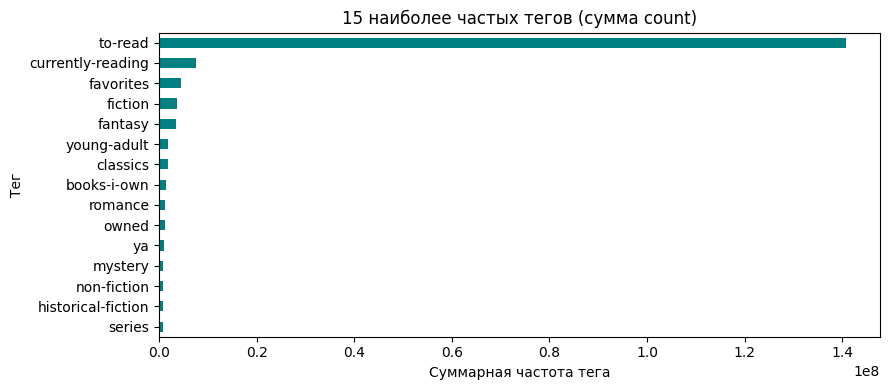

Топ-10 тегов:
tag_name
to-read              140718761
currently-reading      7507958
favorites              4503173
fiction                3688819
fantasy                3548157
young-adult            1848306
classics               1756920
books-i-own            1317235
romance                1231926
owned                  1224279
Name: count, dtype: int64


In [ ]:
tag_stats = (book_tags.merge(tags, on='tag_id', how='left')
             .groupby('tag_name')['count'].sum().sort_values(ascending=False))
# Служебные теги иипа to-read не считаем жанрами, но отображаем честно.
tag_stats.head(15).sort_values().plot.barh(color='teal')
plt.title('15 наиболее частых тегов (сумма count)')
plt.xlabel('Суммарная частота тега')
plt.ylabel('Тег')
plt.tight_layout()
plt.show()
print('Топ-10 тегов:')
print(tag_stats.head(10))

In [ ]:
n_users = ratings.user_id.nunique()
n_books = ratings.book_id.nunique()
sparsity = 1 - len(ratings) / (n_users * n_books)
print(f'Разреженность матрицы взаимодействий: {sparsity:.2%}')
print('Доля оценок 4–5:', round(ratings.rating.ge(4).mean(), 3))

Разреженность матрицы взаимодействий: 99.82%
Доля оценок 4–5: 0.662


**Выводы по EDA.**

Оценок 4 и 5 действительно много => данные смещены к высоким оценкам. Много пользователей имеют малое кол-во взаимодействий — из-за этого появляется проблема холодного страта. Матрица пользователь–книга очень разреженная => заполнять её обычным плотным массивом не стоит. В `ratings.csv` количество оценок на книгу искусственно ограничено примерно сотней => для анализа «длинного хвоста» лучше использовать `books.ratings_count`

## 2. Разделение на обучение и тест

Оставляем пользователям с числом оценок меньше 5 все их данные в обучении, потому что для них невозможно надежно выделить историю и тест. У остальных откладываем примерно 20% оценок, но хотя бы одну. Для проверки рекомендаций используем только пользователей, у которых в тесте есть книги с оценкой >= 4.



In [ ]:
# Небольшая функция разбиения: у активного пользователя хотя бы 1 оценка уйдёт в тест.
ratings = ratings.sample(frac=1, random_state=SEED).reset_index(drop=True)
ratings['position'] = ratings.groupby('user_id').cumcount()
ratings['n_user'] = ratings.groupby('user_id')['rating'].transform('size')
ratings['test_size'] = np.where(ratings.n_user >= 5,
                                np.maximum(1, np.floor(ratings.n_user * 0.2).astype(int)), 0)
test_mask = ratings['position'] < ratings['test_size']
train = ratings.loc[~test_mask, ['user_id', 'book_id', 'rating']].copy()
test = ratings.loc[test_mask, ['user_id', 'book_id', 'rating']].copy()
print('Train:', len(train), '| Test:', len(test))
assert not set(zip(train.user_id, train.book_id)) & set(zip(test.user_id, test.book_id))

Train: 806226 | Test: 173252


## 3. Популярные книги

Отсортируем книги по среднему рейтингу в обучении, но потребуем минимум 50 оценок. Уже прочитанные книги исключаем. Для нового пользователя можно показывать тот же список.

In [ ]:
popularity = (train.groupby('book_id').rating
              .agg(['mean', 'count']).query('count >= 50')
              .sort_values(['mean', 'count'], ascending=False))
pop_rank = popularity.index.to_numpy()
book_names = books.set_index('id')['title'].fillna('Без названия')

def popular_recommendations(user_id=None, N=5):
    seen = set(train.loc[train.user_id == user_id, 'book_id']) if user_id is not None else set()
    ids = [int(b) for b in pop_rank if b not in seen][:N]
    return pd.DataFrame({'book_id': ids, 'title': book_names.reindex(ids).values})

print(popular_recommendations(N=5).to_string(index=False))

 book_id                                                    title
    6920                      The Indispensable Calvin and Hobbes
    5207 The Days Are Just Packed: A Calvin and Hobbes Collection
    7947                                          ESV Study Bible
    9566  Attack of the Deranged Mutant Killer Monster Snow Goons
    3275   Harry Potter Boxed Set, Books 1-5 (Harry Potter, #1-5)


## 4. Контентная модель: TF-IDF

Создадим текст из названия и топ-10 тегов каждой книги. Чтобы текст не состоял только из to-read и похожих меток, исключим несколько служебных тегов

In [16]:
service_tags = {'to-read', 'currently-reading', 'owned', 'favorites', 'books-i-own',
                'default', 'to-buy', 'kindle', 'library', 'ebook', 'ebooks'}
book_tag_names = (book_tags.merge(tags, on='tag_id')
                  .query('tag_name not in @service_tags')
                  .sort_values('count', ascending=False)
                  .groupby('goodreads_book_id').head(10)
                  .groupby('goodreads_book_id')['tag_name'].agg(' '.join))
content_books = books[['id', 'book_id', 'original_title', 'title']].copy()
content_books['text'] = (content_books.original_title.fillna(content_books.title).fillna('')
                         + ' ' + content_books.book_id.map(book_tag_names).fillna(''))
tfidf = TfidfVectorizer(stop_words='english', max_features=15000)
text_matrix = tfidf.fit_transform(content_books.text)
content_positions = pd.Series(np.arange(len(content_books)), index=content_books.id)

def get_similar_books(book_id, N=5):
    if book_id not in content_positions.index:
        return pd.DataFrame(columns=['book_id', 'title', 'similarity'])
    idx = int(content_positions[book_id])
    similarity = cosine_similarity(text_matrix[idx], text_matrix).ravel()
    similarity[idx] = -1
    nearest = np.argsort(similarity)[::-1][:N]
    ids = content_books.iloc[nearest].id.to_numpy()
    return pd.DataFrame({'book_id': ids, 'title': book_names.reindex(ids).values,
                         'similarity': similarity[nearest].round(3)})

print('Похожие на:', book_names.loc[1])
print(get_similar_books(1).to_string(index=False))

Похожие на: The Hunger Games (The Hunger Games, #1)
 book_id                                                    title  similarity
     507 The Hunger Games Trilogy Boxset (The Hunger Games, #1-3)       0.825
    6224     The World of the Hunger Games (Hunger Games Trilogy)       0.765
    1355                           The Hunger Games Tribute Guide       0.740
    1820                                        Hunger (Gone, #2)       0.739
      17                     Catching Fire (The Hunger Games, #2)       0.699


## 5. Item-based collaborative filtering

Вместо плотной матрицы создаём csr_matrix. При поиске рекомендаций сравниваем книги-кандидаты с книгами, которые оценил пользоватеь. Поэтому нет необходимости считать и хранить все 100 млн пар книг.

Сходство - косинус между векторами пользовательских оценок. Для предсказания берём до 10 самых похожих прочитанных книг и считаем взвешенное среднее их оценок. Если похожих книг не нашлось, берём среднюю оценку пользователя (для нового пользователя - общий средний рейтинг).

In [17]:
user_ids = np.sort(train.user_id.unique())
item_ids = np.sort(books.id.unique())
user_index = pd.Series(np.arange(len(user_ids)), index=user_ids)
item_index = pd.Series(np.arange(len(item_ids)), index=item_ids)
row = user_index.loc[train.user_id].to_numpy()
col = item_index.loc[train.book_id].to_numpy()
R = csr_matrix((train.rating.to_numpy(dtype=np.float32), (row, col)),
               shape=(len(user_ids), len(item_ids)))
print('Размер матрицы:', R.shape, '| Ненулевых элементов:', R.nnz)

# Нормолизуем векторы книг, чтобы скалярное произведение стало косинусным сходством.
item_user = R.T.tocsr()
norms = np.sqrt(item_user.multiply(item_user).sum(axis=1)).A1
norms[norms == 0] = 1
normalized_items = item_user.multiply(1 / norms[:, None]).tocsr()
user_history = {u: (group.book_id.to_numpy(), group.rating.to_numpy(dtype=float))
                for u, group in train.groupby('user_id')}
global_mean = float(train.rating.mean())

def item_cf_scores(user_id, candidate_ids, neighbors=10):
    candidate_ids = np.asarray(candidate_ids, dtype=int)
    if user_id not in user_history:
        return np.full(len(candidate_ids), global_mean)
    seen_ids, seen_ratings = user_history[user_id]
    ci = item_index.reindex(candidate_ids)
    hi = item_index.reindex(seen_ids)
    # Все книги из каталога существуют в item_index.
    sims = (normalized_items[ci.to_numpy(dtype=int)] @
            normalized_items[hi.to_numpy(dtype=int)].T).toarray()
    scores = np.full(len(candidate_ids), seen_ratings.mean(), dtype=float)
    for j in range(len(candidate_ids)):
        # Не учитываем отрицательные и нулевые сходства.
        best = np.argsort(sims[j])[-neighbors:]
        weights = sims[j, best]
        if weights.sum() > 0:
            scores[j] = np.dot(weights, seen_ratings[best]) / weights.sum()
    return scores

print('Пример предсказаний Item-CF:', item_cf_scores(int(user_ids[0]), [1, 2, 3]))

Размер матрицы: (53424, 10000) | Ненулевых элементов: 806226
Пример предсказаний Item-CF: [3.         3.66666667 3.66666667]


**Сложность Item-CF.**

Если заранее вычислять сходство всех книг, потребуется примерно O(B^2 * X) операций в простом варианте и O(B^2) памяти, где B - книги, X - пользователи. Здесь применена разреженная матрица и сходство вычисляется только для нужных кандидатов и истории пользователя. Для большого сервиса можно заранее хранить лишь топ-20/50 соседей каждой книги, а не полную матрицу.

## 6. Матричное разложение — SVD

Используем TruncatedSVD из scikit-learn: раскладываем разреженную матрицу оценок на небольшое число скрытых факторов. Чтобы нули не воспринимались как реальные оценки, предварительно вычитаем средний рейтинг каждого пользователя только из его поставленных оценок. Незаполненные клетки остаются нулевыми

In [18]:
# Центрирование не нулевых оценок относительно среднего пользователя.
user_means = np.asarray(R.sum(axis=1)).ravel() / np.maximum(1, R.getnnz(axis=1))
centered = R.copy()
centered.data = centered.data - np.repeat(user_means, np.diff(centered.indptr))
svd = TruncatedSVD(n_components=40, n_iter=5, random_state=SEED)
user_factors = svd.fit_transform(centered)
item_factors = svd.components_.T
print('Объяснённая доля дисперсии:', round(svd.explained_variance_ratio_.sum(), 3))

def svd_scores(user_id, candidate_ids):
    candidate_ids = np.asarray(candidate_ids, dtype=int)
    if user_id not in user_index.index:
        return np.full(len(candidate_ids), global_mean)
    uid = int(user_index[user_id])
    cols = item_index.reindex(candidate_ids).to_numpy(dtype=int)
    return np.clip(user_means[uid] + user_factors[uid] @ item_factors[cols].T, 1, 5)

def get_recommendations(user_id, N=5):
    seen = set(user_history[user_id][0]) if user_id in user_history else set()
    candidates = np.array([b for b in item_ids if b not in seen])
    scores = svd_scores(user_id, candidates)
    best = np.argsort(scores)[::-1][:N]
    ids = candidates[best]
    return pd.DataFrame({'book_id': ids, 'title': book_names.reindex(ids).values,
                         'predicted_rating': np.round(scores[best], 3)})

example_user = int(user_ids[100])
print('Рекомендации SVD пользователю', example_user)
print(get_recommendations(example_user).to_string(index=False))

Объяснённая доля дисперсии: 0.028
Рекомендации SVD пользователю 101
 book_id                             title  predicted_rating
     111      The Memory Keeper's Daughter             4.003
     608                  Love You Forever             4.002
    1267 To the Nines (Stephanie Plum, #9)             4.002
      79                       The Odyssey             4.002
     977    Inferno (The Divine Comedy #1)             4.002


In [19]:
# RMSE на отложенных оценках тех пользователей и книг, которые известны модели.
test_known = test[test.user_id.isin(user_index.index) & test.book_id.isin(item_index.index)].copy()
# Предсказание пачками позволяет избежать длительного цикла по каждой строке.
u_idx = user_index.loc[test_known.user_id].to_numpy()
b_idx = item_index.loc[test_known.book_id].to_numpy()
svd_pred = np.clip(user_means[u_idx] + np.einsum('ij,ij->i',
                   user_factors[u_idx], item_factors[b_idx]), 1, 5)
rmse = np.sqrt(np.mean((test_known.rating.to_numpy() - svd_pred) ** 2))
print(f'RMSE SVD на тестовых оценках: {rmse:.4f}')

RMSE SVD на тестовых оценках: 0.8600


## 7. Сравнение по Precision@5, Recall@5, nDCG@5

Положительными считаем книги из теста с оценкой 4 или 5. Для каждого пользователя сравниваем модели на одном и том же наборе: тестовые книги пользователя +100 случайных непрочитанных книг (не из его train/test). Оценки для дополнительных книг неизвестны, поэтому для учебной офлайн-оценки считаем их нерелевантными. Это sampled evaluation, а не полноценная проверка рекомендаций по всему каталогу то етсь результат сильно зависит от числа отрицательных кандидатов.

Для контроля времени проверяем до 200 пользователей с положительными тестовыми оценками. Content-based здесь не оценивается => модель решает другую задачу (похожие на конкретную книгу), а не ранжирование для пользователя.

Число тестовых пользователей: 200
            Precision@5  Recall@5  nDCG@5
Popularity        0.037    0.0508  0.0507
Item-CF           0.025    0.0449  0.0338
SVD               0.080    0.0563  0.0915


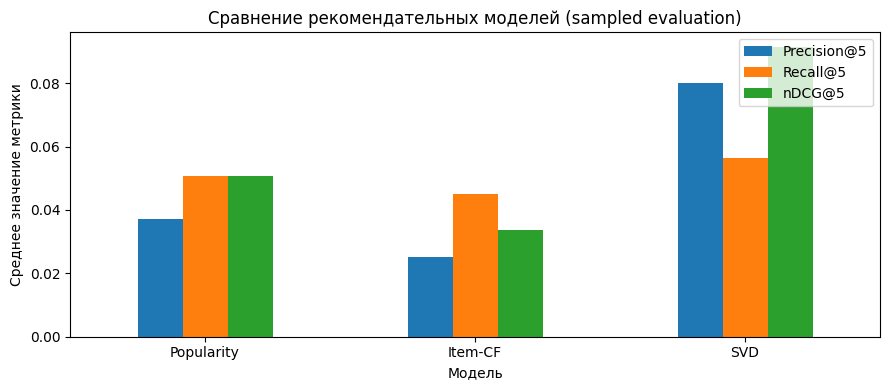

In [20]:
K = 5
MAX_USERS = 200
NEGATIVES = 100
positive_test = test[test.rating >= 4].groupby('user_id').book_id.apply(set)
valid_users = positive_test.index.intersection(user_ids)
eval_users = rng.choice(valid_users.to_numpy(), size=min(MAX_USERS, len(valid_users)), replace=False)
all_user_test = test.groupby('user_id').book_id.apply(set).to_dict()

def ranking_metrics(recommended, relevant, k=K):
    rec = list(recommended[:k])
    hits = np.array([int(b in relevant) for b in rec])
    precision = hits.sum() / k
    recall = hits.sum() / len(relevant) if relevant else 0.0
    dcg = (hits / np.log2(np.arange(2, len(hits) + 2))).sum()
    ideal_hits = min(len(relevant), k)
    idcg = (1 / np.log2(np.arange(2, ideal_hits + 2))).sum()
    ndcg = dcg / idcg if idcg > 0 else 0.0
    return precision, recall, ndcg

results = {'Popularity': [], 'Item-CF': [], 'SVD': []}
for u in eval_users:
    u = int(u)
    relevant = positive_test.loc[u]
    seen, _ = user_history[u]
    excluded = set(seen) | all_user_test[u]
    negatives_pool = np.array([b for b in item_ids if b not in excluded], dtype=int)
    negatives = rng.choice(negatives_pool, size=min(NEGATIVES, len(negatives_pool)), replace=False)
    candidates = np.unique(np.concatenate([list(all_user_test[u]), negatives])).astype(int)

    # Один набор кандидатов на все три модели, без обучающих книг пользователя.
    pop_scores = popularity['mean'].reindex(candidates).fillna(0).to_numpy()
    cf_scores = item_cf_scores(u, candidates)
    mf_scores = svd_scores(u, candidates)
    for name, scores in [('Popularity', pop_scores), ('Item-CF', cf_scores), ('SVD', mf_scores)]:
        top = candidates[np.argsort(-scores, kind='stable')[:K]]
        results[name].append(ranking_metrics(top, relevant))

summary = pd.DataFrame({name: np.mean(rows, axis=0) for name, rows in results.items()},
                       index=[f'Precision@{K}', f'Recall@{K}', f'nDCG@{K}']).T
print('Число тестовых пользователей:', len(eval_users))
print(summary.round(4).to_string())
summary.plot.bar(rot=0)
plt.title('Сравнение рекомендательных моделей (sampled evaluation)')
plt.ylabel('Среднее значение метрики')
plt.xlabel('Модель')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 8. Гибридная система и выводы


1. Если пользователь новый и не оставил оценок - показывать популярные книги.
2. Если у пользователя есть история - использовать SVD (или Item-CF, если по таблице метрик он лучше).
3. Если книга новая и у неё нет оценок — показывать её в подборках похожих книг по тегам и названию (TF-IDF).

Это позволяет частично решить холодный старт без сложных нейросетей.

In [26]:
best_model = summary['nDCG@5'].idxmax()
print('Лучшая модель по nDCG@5 в этом эксперименте:', best_model)
print()
print('Сильные/слабые стороны:')
print('- Popularity: очень простая и подходит новичкам, но не учитывает личный вкус.')
print('- Content TF-IDF: может рекомендовать новые книги, но зависит от качества тегов.')
print('- Item-CF: использует поведение читателей, но страдает при малом числе совместных оценок.')
print('- SVD: учитывает скрытые предпочтения и компактно хранит факторы, но новые книги и пользователи без оценок для него сложны.')
print()
print('Идеи улучшения: убрать служебные теги, добавить авторов и описания, обучить Surprise SVD,')
print('подобрать гиперпараметры и оценить качество на большем числе пользователей.')

Лучшая модель по nDCG@5 в этом эксперименте: SVD

Сильные/слабые стороны:
- Popularity: очень простая и подходит новичкам, но не учитывает личный вкус.
- Content TF-IDF: может рекомендовать новые книги, но зависит от качества тегов.
- Item-CF: использует поведение читателей, но страдает при малом числе совместных оценок.
- SVD: учитывает скрытые предпочтения и компактно хранит факторы, но новые книги и пользователи без оценок для него сложны.

Идеи улучшения: убрать служебные теги, добавить авторов и описания, обучить Surprise SVD,
подобрать гиперпараметры и оценить качество на большем числе пользователей.
